# Bike Demand Model — Training, Comparison and Saving

**Goal:** predict `cnt` (bike rentals per hour) so operations knows how many bikes are needed, hour by hour.

**Inputs:** the preprocessed files `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`
(chronological split: train = Jan 2011 → 7 Aug 2012, test = 7 Aug 2012 → Dec 2012).

**Plan**
1. Load data and set up time-series cross-validation
2. Baseline (hour × working-day average) — every model must beat this
3. Train and compare: Linear Regression, Random Forest, Gradient Boosting (HistGB)
4. Tune the best model with `TimeSeriesSplit` cross-validation
5. Final evaluation on the untouched test set
6. Feature importance and error analysis
7. Save the model + metadata, and show how to load it for prediction

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train = pd.read_csv('X_train.csv'); X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv')['cnt']; y_test = pd.read_csv('y_test.csv')['cnt']
FEATURES = X_train.columns.tolist()
print('Features:', FEATURES)
print('Train', X_train.shape, ' Test', X_test.shape)

tscv = TimeSeriesSplit(n_splits=5)   # always validate on data that comes AFTER the training part
RANDOM_STATE = 42

Features: ['yr', 'mnth', 'hr', 'holiday', 'workingday', 'weathersit', 'hum', 'windspeed', 'temp_avg', 'low_demand_hour']
Train (13903, 10)  Test (3476, 10)


## Evaluation helper
- **MAE**: average error in bikes per hour (easiest to explain)
- **RMSE**: punishes big misses more (important at peaks, where shortages happen)
- **R²**: share of the variation in demand the model explains

In [2]:
results = []
def evaluate(name, y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    row = {'Model': name,
           'MAE': mean_absolute_error(y_true, y_pred),
           'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
           'R2': r2_score(y_true, y_pred)}
    results.append(row)
    print(f"{name:32s} MAE={row['MAE']:6.1f}  RMSE={row['RMSE']:6.1f}  R2={row['R2']:.3f}")
    return y_pred

## 1. Baseline — average demand for each hour × working-day
A "dumb" rule an operations manager could use with a spreadsheet. Any ML model must clearly beat it to be worth deploying.

In [3]:
lookup = pd.concat([X_train[['hr', 'workingday']], y_train], axis=1).groupby(['hr', 'workingday'])['cnt'].mean()
base_pred = X_test.set_index(['hr', 'workingday']).index.map(lookup).values
_ = evaluate('Baseline (hour x workingday avg)', y_test, base_pred)

Baseline (hour x workingday avg) MAE= 101.6  RMSE= 144.9  R2=0.568


## 2. Candidate models
Target is skewed (many quiet hours, few huge peaks), so each model is trained on `log1p(cnt)` and predictions are converted back automatically with `TransformedTargetRegressor`.

In [4]:
def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

candidates = {
    'Linear Regression': log_target(make_pipeline(StandardScaler(), LinearRegression())),
    'Random Forest': log_target(RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                      n_jobs=-1, random_state=RANDOM_STATE)),
    'Gradient Boosting (HistGB)': log_target(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}

cv_rows = []
for name, model in candidates.items():
    cv = -cross_val_score(model, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=1)
    cv_rows.append([name, cv.mean(), cv.std()])
print(pd.DataFrame(cv_rows, columns=['Model', 'CV MAE (mean)', 'CV MAE (std)']).round(1).to_string(index=False))

                     Model  CV MAE (mean)  CV MAE (std)
         Linear Regression           93.0          24.1
             Random Forest           56.0          16.0
Gradient Boosting (HistGB)           48.3          12.1


The CV scores come only from the training period, so the test set is still untouched. Now fit each model on the full training set and check it on the test set.

In [5]:
test_preds = {}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    test_preds[name] = evaluate(name, y_test, model.predict(X_test))

Linear Regression                MAE= 111.4  RMSE= 166.3  R2=0.431
Random Forest                    MAE=  52.2  RMSE=  79.5  R2=0.870
Gradient Boosting (HistGB)       MAE=  50.4  RMSE=  76.9  R2=0.878


## 3. Tune the gradient boosting model
Randomized search over the main hyper-parameters, scored with time-series CV (no future data leaks into any fold).

In [6]:
param_dist = {
    'regressor__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'regressor__max_iter': [300, 500, 800],
    'regressor__max_leaf_nodes': [15, 31, 63],
    'regressor__min_samples_leaf': [10, 20, 40],
    'regressor__l2_regularization': [0.0, 0.1, 1.0],
}
search = RandomizedSearchCV(
    log_target(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_dist, n_iter=15, cv=tscv, scoring='neg_mean_absolute_error',
    random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print('Best CV MAE:', round(-search.best_score_, 1))
print('Best params:', {k.replace('regressor__', ''): v for k, v in search.best_params_.items()})

best_model = search.best_estimator_
test_preds['Tuned HistGB'] = evaluate('Tuned HistGB', y_test, best_model.predict(X_test))

Best CV MAE: 46.3
Best params: {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 800, 'learning_rate': 0.08, 'l2_regularization': 0.1}
Tuned HistGB                     MAE=  48.3  RMSE=  74.0  R2=0.887


## 4. Final comparison on the test set

In [7]:
summary = pd.DataFrame(results).drop_duplicates('Model', keep='last').sort_values('MAE').round(3)
print(summary.to_string(index=False))
base_mae = summary.loc[summary.Model.str.startswith('Baseline'), 'MAE'].iloc[0]
best_row = summary.iloc[0]
print(f"\nBest model: {best_row.Model} — {100 * (1 - best_row.MAE / base_mae):.0f}% lower MAE than the baseline")

                           Model     MAE    RMSE    R2
                    Tuned HistGB  48.347  74.015 0.887
      Gradient Boosting (HistGB)  50.370  76.918 0.878
                   Random Forest  52.158  79.486 0.870
Baseline (hour x workingday avg) 101.550 144.917 0.568
               Linear Regression 111.356 166.280 0.431

Best model: Tuned HistGB — 52% lower MAE than the baseline


## 5. How well does it follow real demand?
One week from the test period (weekday peaks and the weekend hill are both visible), actual vs predicted.

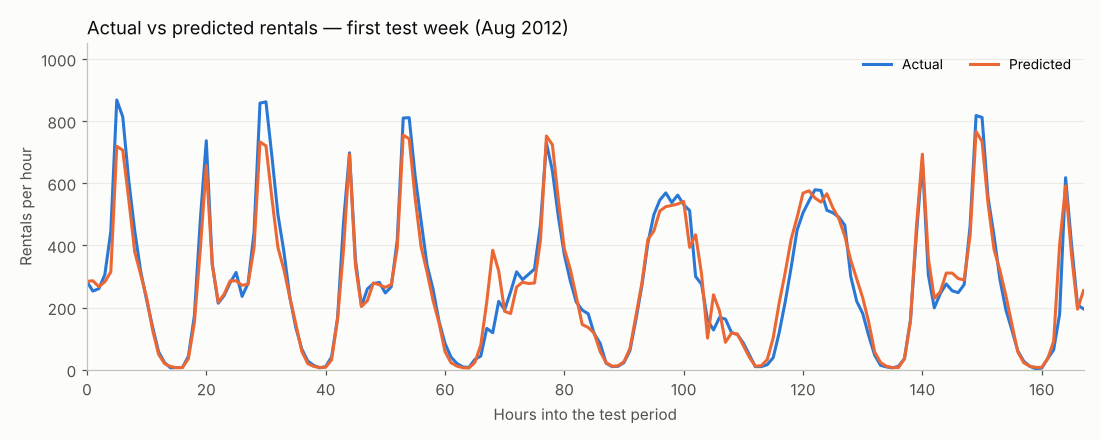

In [8]:
pred_best = test_preds[best_row.Model]
week = slice(0, 24 * 7)
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb')
ax.plot(np.arange(len(y_test))[week], y_test.values[week], color='#2a78d6', lw=2, label='Actual')
ax.plot(np.arange(len(y_test))[week], pred_best[week], color='#eb6834', lw=2, label='Predicted')
ax.set_title('Actual vs predicted rentals — first test week (Aug 2012)', loc='left', fontsize=12, color='#0b0b0b')
ax.set_xlabel('Hours into the test period', color='#52514e'); ax.set_ylabel('Rentals per hour', color='#52514e')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
for s in ['left', 'bottom']: ax.spines[s].set_color('#c3c2b7')
ax.tick_params(colors='#52514e'); ax.grid(axis='y', color='#ecebe7', lw=0.8); ax.set_axisbelow(True)
ax.set_xlim(0, 24 * 7 - 1); ax.set_ylim(0, 1050)
ax.legend(frameon=False, loc='upper right', ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

## 6. Error analysis — where does the model miss?
Errors matter most at peak hours (that is when riders can't find bikes).

In [9]:
err = pd.DataFrame({'hr': X_test.hr, 'workingday': X_test.workingday,
                    'actual': y_test, 'pred': pred_best})
err['abs_err'] = (err.actual - err.pred).abs()
err['period'] = np.select(
    [err.hr.isin([7, 8, 17, 18]) & (err.workingday == 1), X_test.low_demand_hour == 1],
    ['Commute peak', 'Night (low demand)'], 'Other daytime')
tab = err.groupby('period').agg(avg_actual=('actual', 'mean'), MAE=('abs_err', 'mean'))
tab['error_%'] = 100 * tab.MAE / tab.avg_actual
print(tab.round(1).to_string())
under = (err.pred < err.actual)
print(f"\nModel under-predicts in {under.mean():.0%} of hours")

                    avg_actual    MAE  error_%
period                                        
Commute peak             599.3  113.6     19.0
Night (low demand)        43.6   13.3     30.5
Other daytime            282.1   53.0     18.8

Model under-predicts in 65% of hours


## 7. Which features drive the prediction?
Permutation importance: how much test MAE gets worse when one feature is randomly shuffled.

In [10]:
pi = permutation_importance(best_model, X_test, y_test, scoring='neg_mean_absolute_error',
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print('MAE increase when feature is shuffled (bikes/hour):')
print(imp.round(1).to_string())

MAE increase when feature is shuffled (bikes/hour):
hr                 120.0
workingday          41.3
temp_avg            27.3
low_demand_hour     24.7
hum                  9.8
mnth                 4.0
weathersit           3.9
holiday              1.2
windspeed            0.4
yr                   0.0


## 8. Retrain on all data and save
The test set has done its job (honest evaluation). For deployment, retrain the chosen settings on train + test so the model also learns the most recent months, then save it with metadata describing exactly what inputs it expects.

In [11]:
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
final_model = log_target(HistGradientBoostingRegressor(
    random_state=RANDOM_STATE,
    **{k.replace('regressor__', ''): v for k, v in search.best_params_.items()}))
final_model.fit(X_all, y_all)

joblib.dump(final_model, 'bike_demand_model.joblib')
metadata = {
    'model': 'HistGradientBoostingRegressor on log1p(cnt)',
    'features_in_order': FEATURES,
    'preprocessing': {
        'temp_avg': '(temp + atemp) / 2, both in the dataset normalized units',
        'hum_zero_fill': 0.624,
        'low_demand_hours': [23, 0, 1, 2, 3, 4, 5],
        'dropped': ['instant', 'dteday', 'season', 'weekday', 'casual', 'registered', 'temp', 'atemp'],
    },
    'test_metrics_before_retrain': {k: round(float(best_row[k]), 3) for k in ['MAE', 'RMSE', 'R2']},
    'best_params': {k.replace('regressor__', ''): v for k, v in search.best_params_.items()},
}
json.dump(metadata, open('model_metadata.json', 'w'), indent=2)
print('Saved bike_demand_model.joblib and model_metadata.json')

Saved bike_demand_model.joblib and model_metadata.json


## 9. Load the saved model and predict (how deployment will use it)

In [12]:
model = joblib.load('bike_demand_model.joblib')
meta = json.load(open('model_metadata.json'))

def make_features(yr, mnth, hr, holiday, workingday, weathersit, hum, windspeed, temp, atemp):
    hum = meta['preprocessing']['hum_zero_fill'] if hum == 0 else hum
    row = dict(yr=yr, mnth=mnth, hr=hr, holiday=holiday, workingday=workingday,
               weathersit=weathersit, hum=hum, windspeed=windspeed,
               temp_avg=(temp + atemp) / 2,
               low_demand_hour=int(hr in meta['preprocessing']['low_demand_hours']))
    return pd.DataFrame([row])[meta['features_in_order']]

examples = {
    'Weekday 8 am, clear, warm':   make_features(1, 6, 8, 0, 1, 1, 0.55, 0.15, 0.66, 0.62),
    'Weekday 3 am, clear, warm':   make_features(1, 6, 3, 0, 1, 1, 0.70, 0.10, 0.60, 0.58),
    'Sunday 1 pm, clear, warm':    make_features(1, 6, 13, 0, 0, 1, 0.50, 0.20, 0.70, 0.65),
    'Weekday 6 pm, light rain':    make_features(1, 11, 18, 0, 1, 3, 0.90, 0.25, 0.30, 0.29),
}
for desc, X in examples.items():
    print(f"{desc:28s} -> {model.predict(X)[0]:5.0f} bikes needed")

Weekday 8 am, clear, warm    ->   660 bikes needed
Weekday 3 am, clear, warm    ->     7 bikes needed
Sunday 1 pm, clear, warm     ->   541 bikes needed
Weekday 6 pm, light rain     ->   162 bikes needed


## Summary
- The tuned gradient boosting model is the best, far ahead of the baseline and of linear regression (linear models can't capture the two commute peaks from `hr` as a plain number).
- Hour of day and working day dominate the prediction, confirming the hypothesis that the problem is **timing**.
- `yr` shows zero importance only because the test period is all 2012 (yr = 1), so shuffling it changes nothing there. It still matters for capturing growth between years.
- **Known bias:** the model under-predicts in about 65% of hours, and peak-hour errors are the largest in bikes (≈114/hour, ~19%). Training on `log1p(cnt)` pulls predictions slightly below the average. For fleet planning, under-predicting means shortages, so operations should add a safety buffer at peaks (or a quantile model predicting e.g. the 90th percentile of demand).
- Saved files: `bike_demand_model.joblib` (model) and `model_metadata.json` (feature order + preprocessing rules). Deployment must apply the **same** preprocessing before calling `predict`.